In [22]:
import pandas as pd
import numpy as np
df_current = pd.read_csv('application_data.csv')
df_previous = pd.read_csv('previous_application.csv')

# Current

Remove id and target

In [23]:
id_col = "SK_ID_CURR"
target_col = "TARGET"

X_current = df_current.drop(columns=[id_col, target_col])
y_current = df_current[target_col]

In [ ]:
# Categorical columns
cat_cols_current = X_current.select_dtypes(include=["object"]).columns.tolist()

# Numeric columns
num_cols_all_current = X_current.select_dtypes(include=[np.number]).columns.tolist()

# Binary numeric columns: only contain 0/1 after removing NA
binary_cols_current = []

for col in num_cols_all_current:
    vals = X_current[col].dropna().unique()
    if len(vals) <= 2 and set(vals).issubset({0, 1}):
        binary_cols_current.append(col)

# Continuous numerical columns
num_cols_current = [
    col for col in num_cols_all_current
    if col not in binary_cols_current
]

print("categorical:", len(cat_cols_current))
print("binary:", len(binary_cols_current))
print("numerical:", len(num_cols_current))

categorical: 16
binary: 32
numerical: 72


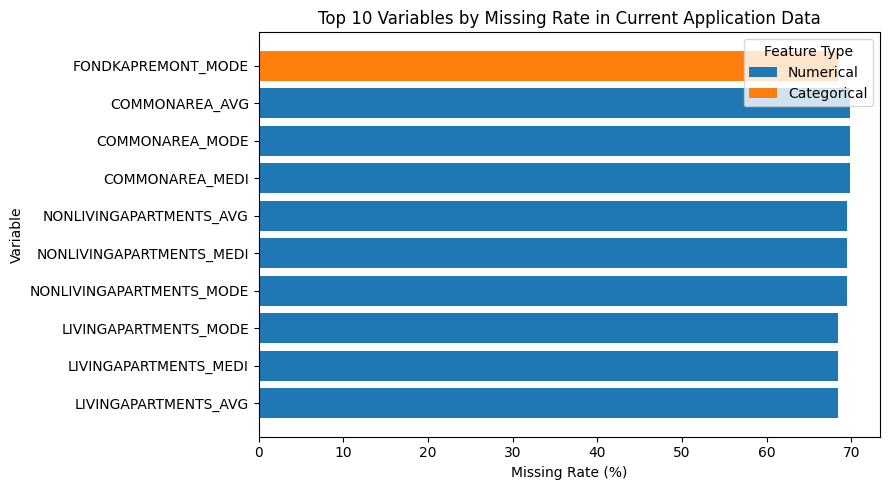

In [ ]:
import matplotlib.pyplot as plt
missing_summary_current = (
    X_current.isna()
    .mean()
    .reset_index()
)

missing_summary_current.columns = ["variable", "missing_rate"]
missing_summary_current["missing_percent"] = missing_summary_current["missing_rate"] * 100

def get_feature_type(col):
    if col in cat_cols_current:
        return "Categorical"
    elif col in binary_cols_current:
        return "Binary"
    elif col in num_cols_current:
        return "Numerical"
    else:
        return "Other"

missing_summary_current["feature_type"] = missing_summary_current["variable"].apply(get_feature_type)

# Top 10 missing variables
top10_missing_current = (
    missing_summary_current
    .sort_values("missing_rate", ascending=False)
    .head(10)
    .sort_values("missing_rate", ascending=True)
)

plt.figure(figsize=(9, 5))

for feature_type in top10_missing_current["feature_type"].unique():
    subset = top10_missing_current[top10_missing_current["feature_type"] == feature_type]
    plt.barh(
        subset["variable"],
        subset["missing_percent"],
        label=feature_type
    )

plt.xlabel("Missing Rate (%)")
plt.ylabel("Variable")
plt.title("Top 10 Variables by Missing Rate in Current Application Data")
plt.legend(title="Feature Type")
plt.tight_layout()
plt.savefig("current_missing_values_top10.png", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# 1. Select numerical housing AVG / MODE / MEDI columns
housing_cols_current = [
    col for col in num_cols_current
    if col.endswith(("_AVG", "_MODE", "_MEDI"))
]

print("Number of numerical housing columns:", len(housing_cols_current))

# 2. Compute Spearman correlation matrix
housing_cor_matrix = (
    X_current[housing_cols_current]
    .corr(method="spearman")
)

# 3. Convert matrix to long format
housing_cor_pairs_current = (
    housing_cor_matrix
    .stack()
    .reset_index()
)

housing_cor_pairs_current.columns = ["var1", "var2", "spearman_cor"]

# 4. Remove self-correlation
housing_cor_pairs_current = housing_cor_pairs_current[
    housing_cor_pairs_current["var1"] != housing_cor_pairs_current["var2"]
].copy()

# 5. Add absolute correlation
housing_cor_pairs_current["abs_cor"] = housing_cor_pairs_current["spearman_cor"].abs()

# 6. Remove duplicated pair directions: A-B and B-A
housing_cor_pairs_current["pair_sorted"] = housing_cor_pairs_current.apply(
    lambda row: " | ".join(sorted([row["var1"], row["var2"]])),
    axis=1
)

housing_cor_pairs_current = housing_cor_pairs_current.drop_duplicates("pair_sorted")

housing_cor_pairs_current = housing_cor_pairs_current.sort_values(
    "abs_cor", ascending=False
)

housing_cor_pairs_current.head(30)

Number of numerical housing columns: 43


,var1,var2,spearman_cor,abs_cor,pair_sorted
160,YEARS_BUILD_AVG,YEARS_BUILD_MEDI,0.998411,0.998411,YEARS_BUILD_AVG | YEARS_BUILD_MEDI
116,YEARS_BEGINEXPLUATATION_AVG,YEARS_BEGINEXPLUATATION_MEDI,0.997432,0.997432,YEARS_BEGINEXPLUATATION_AVG | YEARS_BEGINEXPLU...
424,LANDAREA_AVG,LANDAREA_MEDI,0.996279,0.996279,LANDAREA_AVG | LANDAREA_MEDI
380,FLOORSMIN_AVG,FLOORSMIN_MEDI,0.996223,0.996223,FLOORSMIN_AVG | FLOORSMIN_MEDI
468,LIVINGAPARTMENTS_AVG,LIVINGAPARTMENTS_MEDI,0.996199,0.996199,LIVINGAPARTMENTS_AVG | LIVINGAPARTMENTS_MEDI
204,COMMONAREA_AVG,COMMONAREA_MEDI,0.995734,0.995734,COMMONAREA_AVG | COMMONAREA_MEDI
512,LIVINGAREA_AVG,LIVINGAREA_MEDI,0.995506,0.995506,LIVINGAREA_AVG | LIVINGAREA_MEDI
28,APARTMENTS_AVG,APARTMENTS_MEDI,0.995231,0.995231,APARTMENTS_AVG | APARTMENTS_MEDI
72,BASEMENTAREA_AVG,BASEMENTAREA_MEDI,0.994929,0.994929,BASEMENTAREA_AVG | BASEMENTAREA_MEDI
336,FLOORSMAX_AVG,FLOORSMAX_MEDI,0.994876,0.994876,FLOORSMAX_AVG | FLOORSMAX_MEDI


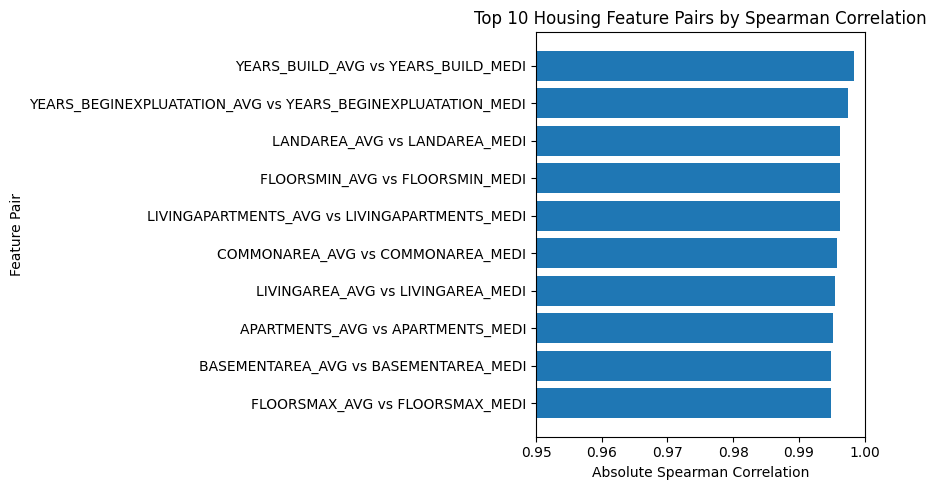

In [10]:
top10_housing_cor = housing_cor_pairs_current.head(10).copy()

top10_housing_cor["pair"] = (
    top10_housing_cor["var1"] + " vs " + top10_housing_cor["var2"]
)

top10_housing_cor = top10_housing_cor.sort_values("abs_cor", ascending=True)

plt.figure(figsize=(9, 5))
plt.barh(top10_housing_cor["pair"], top10_housing_cor["abs_cor"])

plt.xlabel("Absolute Spearman Correlation")
plt.ylabel("Feature Pair")
plt.title("Top 10 Housing Feature Pairs by Spearman Correlation")
plt.xlim(0.95, 1.00)

plt.tight_layout()
plt.savefig("housing_spearman_top10.png", dpi=300, bbox_inches="tight")
plt.show()

In [14]:
# Save confirmed drop list: redundant housing MODE/MEDI features only

drop_housing_mode_medi_current = [
    col for col in housing_cols_current
    if col.endswith(("_MODE", "_MEDI"))
]

drop_candidates_current = drop_housing_mode_medi_current.copy()

print("Confirmed housing MODE/MEDI features to drop:", len(drop_housing_mode_medi_current))
print("Total confirmed features to drop:", len(drop_candidates_current))

drop_candidates_current

Confirmed housing MODE/MEDI features to drop: 29
Total confirmed features to drop: 29


['APARTMENTS_MODE',
 'BASEMENTAREA_MODE',
 'YEARS_BEGINEXPLUATATION_MODE',
 'YEARS_BUILD_MODE',
 'COMMONAREA_MODE',
 'ELEVATORS_MODE',
 'ENTRANCES_MODE',
 'FLOORSMAX_MODE',
 'FLOORSMIN_MODE',
 'LANDAREA_MODE',
 'LIVINGAPARTMENTS_MODE',
 'LIVINGAREA_MODE',
 'NONLIVINGAPARTMENTS_MODE',
 'NONLIVINGAREA_MODE',
 'APARTMENTS_MEDI',
 'BASEMENTAREA_MEDI',
 'YEARS_BEGINEXPLUATATION_MEDI',
 'YEARS_BUILD_MEDI',
 'COMMONAREA_MEDI',
 'ELEVATORS_MEDI',
 'ENTRANCES_MEDI',
 'FLOORSMAX_MEDI',
 'FLOORSMIN_MEDI',
 'LANDAREA_MEDI',
 'LIVINGAPARTMENTS_MEDI',
 'LIVINGAREA_MEDI',
 'NONLIVINGAPARTMENTS_MEDI',
 'NONLIVINGAREA_MEDI',
 'TOTALAREA_MODE']

## Near-zero variance / almost constant review for binary features

In [15]:
# Near-zero variance / almost constant review for binary features

binary_summary_current = []

for col in binary_cols_current:
    prop_0 = (X_current[col] == 0).mean()
    prop_1 = (X_current[col] == 1).mean()
    missing_rate = X_current[col].isna().mean()
    
    binary_summary_current.append({
        "variable": col,
        "prop_0": prop_0,
        "prop_1": prop_1,
        "missing_rate": missing_rate,
        "max_class_prop": max(prop_0, prop_1),
        "minority_class_prop": min(prop_0, prop_1)
    })

binary_distribution_current = (
    pd.DataFrame(binary_summary_current)
    .sort_values("max_class_prop", ascending=False)
    .reset_index(drop=True)
)

binary_distribution_current.head(20)

,variable,prop_0,prop_1,missing_rate,max_class_prop,minority_class_prop
0,FLAG_MOBIL,0.000003,0.999997,0.0,0.999997,0.000003
1,FLAG_DOCUMENT_12,0.999993,0.000007,0.0,0.999993,0.000007
2,FLAG_DOCUMENT_10,0.999977,0.000023,0.0,0.999977,0.000023
3,FLAG_DOCUMENT_2,0.999958,0.000042,0.0,0.999958,0.000042
4,FLAG_DOCUMENT_4,0.999919,0.000081,0.0,0.999919,0.000081
5,FLAG_DOCUMENT_7,0.999808,0.000192,0.0,0.999808,0.000192
6,FLAG_DOCUMENT_17,0.999733,0.000267,0.0,0.999733,0.000267
7,FLAG_DOCUMENT_21,0.999665,0.000335,0.0,0.999665,0.000335
8,FLAG_DOCUMENT_20,0.999493,0.000507,0.0,0.999493,0.000507
9,FLAG_DOCUMENT_19,0.999405,0.000595,0.0,0.999405,0.000595


In [16]:
# Candidate near-constant binary features
near_constant_binary_current = (
    binary_distribution_current[
        binary_distribution_current["max_class_prop"] >= 0.995
    ]
    .copy()
    .reset_index(drop=True)
)

near_constant_binary_current

,variable,prop_0,prop_1,missing_rate,max_class_prop,minority_class_prop
0,FLAG_MOBIL,0.000003,0.999997,0.0,0.999997,0.000003
1,FLAG_DOCUMENT_12,0.999993,0.000007,0.0,0.999993,0.000007
2,FLAG_DOCUMENT_10,0.999977,0.000023,0.0,0.999977,0.000023
3,FLAG_DOCUMENT_2,0.999958,0.000042,0.0,0.999958,0.000042
4,FLAG_DOCUMENT_4,0.999919,0.000081,0.0,0.999919,0.000081
5,FLAG_DOCUMENT_7,0.999808,0.000192,0.0,0.999808,0.000192
6,FLAG_DOCUMENT_17,0.999733,0.000267,0.0,0.999733,0.000267
7,FLAG_DOCUMENT_21,0.999665,0.000335,0.0,0.999665,0.000335
8,FLAG_DOCUMENT_20,0.999493,0.000507,0.0,0.999493,0.000507
9,FLAG_DOCUMENT_19,0.999405,0.000595,0.0,0.999405,0.000595


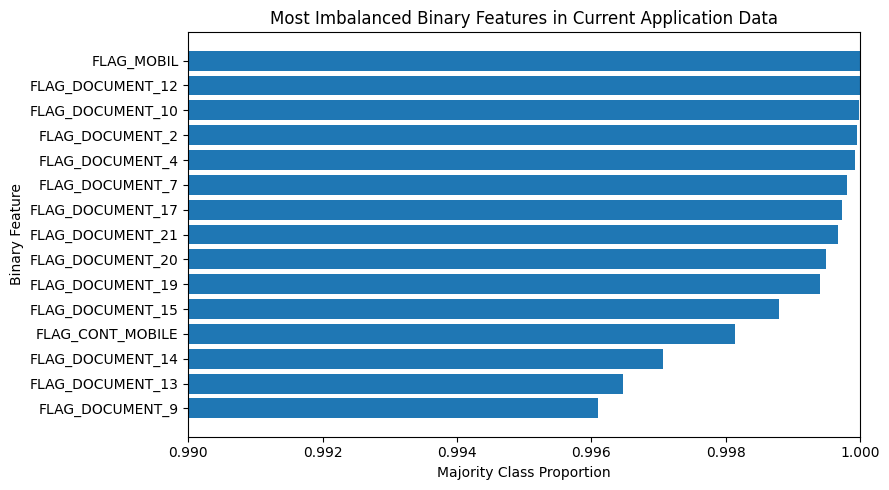

In [17]:
top_binary_constant_current = binary_distribution_current.head(15).copy()
top_binary_constant_current = top_binary_constant_current.sort_values(
    "max_class_prop", ascending=True
)

plt.figure(figsize=(9, 5))
plt.barh(
    top_binary_constant_current["variable"],
    top_binary_constant_current["max_class_prop"]
)

plt.xlabel("Majority Class Proportion")
plt.ylabel("Binary Feature")
plt.title("Most Imbalanced Binary Features in Current Application Data")
plt.xlim(0.99, 1.00)

plt.tight_layout()
plt.show()

In [18]:
# Add near-constant binary features to drop candidates

drop_near_constant_binary_current = near_constant_binary_current["variable"].tolist()

drop_candidates_current = sorted(set(
    drop_candidates_current + drop_near_constant_binary_current
))

print("Housing MODE/MEDI to drop:", len(drop_housing_mode_medi_current))
print("Near-constant binary to drop:", len(drop_near_constant_binary_current))
print("Total confirmed features to drop:", len(drop_candidates_current))

drop_candidates_current

Housing MODE/MEDI to drop: 29
Near-constant binary to drop: 16
Total confirmed features to drop: 45


['APARTMENTS_MEDI',
 'APARTMENTS_MODE',
 'BASEMENTAREA_MEDI',
 'BASEMENTAREA_MODE',
 'COMMONAREA_MEDI',
 'COMMONAREA_MODE',
 'ELEVATORS_MEDI',
 'ELEVATORS_MODE',
 'ENTRANCES_MEDI',
 'ENTRANCES_MODE',
 'FLAG_CONT_MOBILE',
 'FLAG_DOCUMENT_10',
 'FLAG_DOCUMENT_11',
 'FLAG_DOCUMENT_12',
 'FLAG_DOCUMENT_13',
 'FLAG_DOCUMENT_14',
 'FLAG_DOCUMENT_15',
 'FLAG_DOCUMENT_17',
 'FLAG_DOCUMENT_19',
 'FLAG_DOCUMENT_2',
 'FLAG_DOCUMENT_20',
 'FLAG_DOCUMENT_21',
 'FLAG_DOCUMENT_4',
 'FLAG_DOCUMENT_7',
 'FLAG_DOCUMENT_9',
 'FLAG_MOBIL',
 'FLOORSMAX_MEDI',
 'FLOORSMAX_MODE',
 'FLOORSMIN_MEDI',
 'FLOORSMIN_MODE',
 'LANDAREA_MEDI',
 'LANDAREA_MODE',
 'LIVINGAPARTMENTS_MEDI',
 'LIVINGAPARTMENTS_MODE',
 'LIVINGAREA_MEDI',
 'LIVINGAREA_MODE',
 'NONLIVINGAPARTMENTS_MEDI',
 'NONLIVINGAPARTMENTS_MODE',
 'NONLIVINGAREA_MEDI',
 'NONLIVINGAREA_MODE',
 'TOTALAREA_MODE',
 'YEARS_BEGINEXPLUATATION_MEDI',
 'YEARS_BEGINEXPLUATATION_MODE',
 'YEARS_BUILD_MEDI',
 'YEARS_BUILD_MODE']

In [ ]:
# Apply confirmed feature selection

X_current_selected = X_current.drop(columns=drop_candidates_current)

df_current_selected = pd.concat(
    [df_current[["SK_ID_CURR", "TARGET"]], X_current_selected],
    axis=1
)

print("Original shape:", df_current.shape)
print("Selected shape:", df_current_selected.shape)

Original shape: (307511, 122)
Selected shape: (307511, 77)


In [ ]:
print(X_current_selected.shape)

(307511, 75)


feature selection结束后的df为X_current_selected

# If a person doesn't owned a car, the age of car will be marked as na, but it can't be treat as missing value

In [36]:
# Re-identify binary columns after feature selection

num_cols_all_selected = X_current_selected.select_dtypes(include=[np.number]).columns.tolist()

binary_cols_selected = []

for col in num_cols_all_selected:
    vals = X_current_selected[col].dropna().unique()
    if len(vals) <= 2 and set(vals).issubset({0, 1}):
        binary_cols_selected.append(col)

print("Number of binary columns after feature selection:", len(binary_cols_selected))
binary_cols_selected

Number of binary columns after feature selection: 16


['FLAG_EMP_PHONE',
 'FLAG_WORK_PHONE',
 'FLAG_PHONE',
 'FLAG_EMAIL',
 'REG_REGION_NOT_LIVE_REGION',
 'REG_REGION_NOT_WORK_REGION',
 'LIVE_REGION_NOT_WORK_REGION',
 'REG_CITY_NOT_LIVE_CITY',
 'REG_CITY_NOT_WORK_CITY',
 'LIVE_CITY_NOT_WORK_CITY',
 'FLAG_DOCUMENT_3',
 'FLAG_DOCUMENT_5',
 'FLAG_DOCUMENT_6',
 'FLAG_DOCUMENT_8',
 'FLAG_DOCUMENT_16',
 'FLAG_DOCUMENT_18']

In [35]:
binary_review_selected = pd.DataFrame({
    "binary_col": binary_cols_selected
})

binary_review_selected["group"] = binary_review_selected["binary_col"].apply(
    lambda x: (
        "ownership" if "OWN" in x else
        "phone/contact" if "PHONE" in x or "EMAIL" in x or "MOBILE" in x else
        "region/city mismatch" if "REG_" in x or "LIVE_" in x else
        "document" if "DOCUMENT" in x else
        "other"
    )
)

binary_review_selected

,binary_col,group
0,FLAG_EMP_PHONE,phone/contact
1,FLAG_WORK_PHONE,phone/contact
2,FLAG_PHONE,phone/contact
3,FLAG_EMAIL,phone/contact
4,REG_REGION_NOT_LIVE_REGION,region/city mismatch
5,REG_REGION_NOT_WORK_REGION,region/city mismatch
6,LIVE_REGION_NOT_WORK_REGION,region/city mismatch
7,REG_CITY_NOT_LIVE_CITY,region/city mismatch
8,REG_CITY_NOT_WORK_CITY,region/city mismatch
9,LIVE_CITY_NOT_WORK_CITY,region/city mismatch


In [30]:
# Categorical columns after feature selection
cat_cols_selected = X_current_selected.select_dtypes(include=["object"]).columns.tolist()

# Find categorical columns with exactly 2 unique non-missing values
binary_cat_cols_selected = []

for col in cat_cols_selected:
    vals = X_current_selected[col].dropna().unique()
    if len(vals) == 2:
        binary_cat_cols_selected.append(col)

print("Binary categorical columns:", len(binary_cat_cols_selected))
binary_cat_cols_selected

Binary categorical columns: 4


['NAME_CONTRACT_TYPE',
 'FLAG_OWN_CAR',
 'FLAG_OWN_REALTY',
 'EMERGENCYSTATE_MODE']

In [31]:
for col in binary_cat_cols_selected:
    print("\n", col)
    print(X_current_selected[col].value_counts(dropna=False))


 NAME_CONTRACT_TYPE
NAME_CONTRACT_TYPE
Cash loans         278232
Revolving loans     29279
Name: count, dtype: int64

 FLAG_OWN_CAR
FLAG_OWN_CAR
N    202924
Y    104587
Name: count, dtype: int64

 FLAG_OWN_REALTY
FLAG_OWN_REALTY
Y    213312
N     94199
Name: count, dtype: int64

 EMERGENCYSTATE_MODE
EMERGENCYSTATE_MODE
No     159428
NaN    145755
Yes      2328
Name: count, dtype: int64


## Convert true Y/N flag categorical variables to 0/1

In [ ]:

X_current_clean = X_current_selected.copy()

binary_cat_mapping = {
    "FLAG_OWN_CAR": {"N": 0, "Y": 1},
    "FLAG_OWN_REALTY": {"N": 0, "Y": 1}
}

for col, mapping in binary_cat_mapping.items():
    if col in X_current_clean.columns:
        X_current_clean[col] = X_current_clean[col].map(mapping).astype(int)

# Check result
X_current_clean[["FLAG_OWN_CAR", "FLAG_OWN_REALTY"]].head()

,FLAG_OWN_CAR,FLAG_OWN_REALTY
0,0,1
1,0,0
2,1,1
3,0,1
4,0,1


In [34]:
cat_cols_clean = X_current_clean.select_dtypes(include=["object"]).columns.tolist()

num_cols_all_clean = X_current_clean.select_dtypes(include=[np.number]).columns.tolist()

binary_cols_clean = []

for col in num_cols_all_clean:
    vals = X_current_clean[col].dropna().unique()
    if len(vals) <= 2 and set(vals).issubset({0, 1}):
        binary_cols_clean.append(col)

num_cols_clean = [
    col for col in num_cols_all_clean
    if col not in binary_cols_clean
]

print("categorical:", len(cat_cols_clean))
print("binary:", len(binary_cols_clean))
print("numerical:", len(num_cols_clean))

categorical: 14
binary: 18
numerical: 43


## Re-identify binary columns after feature selection

In [ ]:
num_cols_all_selected = X_current_clean.select_dtypes(include=[np.number]).columns.tolist()

binary_cols_selected = []

for col in num_cols_all_selected:
    vals = X_current_selected[col].dropna().unique()
    if len(vals) <= 2 and set(vals).issubset({0, 1}):
        binary_cols_selected.append(col)

print("Number of binary columns after feature selection:", len(binary_cols_selected))
binary_cols_selected

Number of binary columns after feature selection: 16


['FLAG_EMP_PHONE',
 'FLAG_WORK_PHONE',
 'FLAG_PHONE',
 'FLAG_EMAIL',
 'REG_REGION_NOT_LIVE_REGION',
 'REG_REGION_NOT_WORK_REGION',
 'LIVE_REGION_NOT_WORK_REGION',
 'REG_CITY_NOT_LIVE_CITY',
 'REG_CITY_NOT_WORK_CITY',
 'LIVE_CITY_NOT_WORK_CITY',
 'FLAG_DOCUMENT_3',
 'FLAG_DOCUMENT_5',
 'FLAG_DOCUMENT_6',
 'FLAG_DOCUMENT_8',
 'FLAG_DOCUMENT_16',
 'FLAG_DOCUMENT_18']

we don't need to handle documents

In [39]:
pd.crosstab(
    X_current_clean["FLAG_OWN_CAR"],
    X_current_clean["OWN_CAR_AGE"].isna(),
    margins=True
)

OWN_CAR_AGE,False,True,All
FLAG_OWN_CAR,,,
0,0,202924,202924
1,104582,5,104587
All,104582,202929,307511


In [40]:
pd.crosstab(
    X_current_clean["FLAG_OWN_CAR"],
    X_current_clean["OWN_CAR_AGE"].isna(),
    normalize="index"
)

OWN_CAR_AGE,False,True
FLAG_OWN_CAR,,
0,0.000000,1.000000
1,0.999952,0.000048


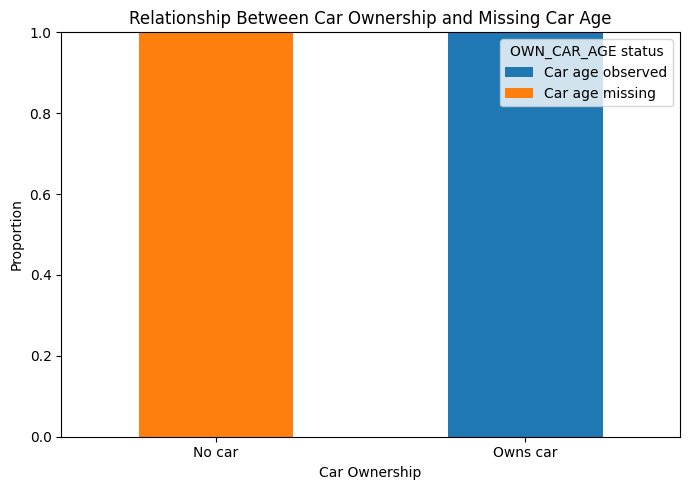

In [44]:

import matplotlib.pyplot as plt
import pandas as pd

# Create proportion table
car_age_missing_prop = pd.crosstab(
    X_current_clean["FLAG_OWN_CAR"],
    X_current_clean["OWN_CAR_AGE"].isna(),
    normalize="index"
)

# Rename for clearer labels
car_age_missing_prop.columns = ["Car age observed", "Car age missing"]
car_age_missing_prop.index = ["No car", "Owns car"]

# Plot
ax = car_age_missing_prop.plot(
    kind="bar",
    stacked=True,
    figsize=(7, 5)
)

plt.xlabel("Car Ownership")
plt.ylabel("Proportion")
plt.title("Relationship Between Car Ownership and Missing Car Age")
plt.legend(title="OWN_CAR_AGE status", loc="upper right")
plt.xticks(rotation=0)
plt.ylim(0, 1)

plt.tight_layout()
plt.savefig("own_car_age_missing_by_car_ownership.png", dpi=300, bbox_inches="tight")
plt.show()

In [42]:
# Check whether car owners have OWN_CAR_AGE = 0
car_owner_age_zero = X_current_clean[
    (X_current_clean["FLAG_OWN_CAR"] == 1) &
    (X_current_clean["OWN_CAR_AGE"] == 0)
]

print("Number of car owners with OWN_CAR_AGE = 0:", car_owner_age_zero.shape[0])
print("Total car owners:", (X_current_clean["FLAG_OWN_CAR"] == 1).sum())
print(
    "Proportion:",
    car_owner_age_zero.shape[0] / (X_current_clean["FLAG_OWN_CAR"] == 1).sum()
)

Number of car owners with OWN_CAR_AGE = 0: 2134
Total car owners: 104587
Proportion: 0.02040406551483454


so we can't impute 0 for people without cars. We use -1 and add indicator.

没有车的信息已经由 FLAG_OWN_CAR = 0 表示；OWN_CAR_AGE_missing 只标记真正“有车但车龄缺失”的情况。

In [45]:
# Special handling for OWN_CAR_AGE

# True missing only: owns car but car age is missing
X_current_clean["OWN_CAR_AGE_missing"] = (
    (X_current_clean["FLAG_OWN_CAR"] == 1) &
    (X_current_clean["OWN_CAR_AGE"].isna())
).astype(int)

# Not applicable: no car, so car age does not exist
X_current_clean.loc[
    (X_current_clean["FLAG_OWN_CAR"] == 0) &
    (X_current_clean["OWN_CAR_AGE"].isna()),
    "OWN_CAR_AGE"
] = -1

# True missing among car owners: impute with car-owner median
car_age_median = X_current_clean.loc[
    (X_current_clean["FLAG_OWN_CAR"] == 1) &
    (X_current_clean["OWN_CAR_AGE"].notna()),
    "OWN_CAR_AGE"
].median()

X_current_clean.loc[
    (X_current_clean["FLAG_OWN_CAR"] == 1) &
    (X_current_clean["OWN_CAR_AGE"].isna()),
    "OWN_CAR_AGE"
] = car_age_median

print("Remaining NA in OWN_CAR_AGE:", X_current_clean["OWN_CAR_AGE"].isna().sum())
print("OWN_CAR_AGE_missing count:", X_current_clean["OWN_CAR_AGE_missing"].sum())

Remaining NA in OWN_CAR_AGE: 0
OWN_CAR_AGE_missing count: 5


## Check relationship between FLAG_OWN_REALTY and housing-related missingness

In [ ]:
housing_avg_cols_clean = [
    col for col in X_current_clean.columns
    if col.endswith("_AVG")
]

housing_avg_missing_rate_by_realty = []

for col in housing_avg_cols_clean:
    temp = pd.crosstab(
        X_current_clean["FLAG_OWN_REALTY"],
        X_current_clean[col].isna(),
        normalize="index"
    )
    
    missing_rate_no_realty = temp.loc[0, True] if (0 in temp.index and True in temp.columns) else 0
    missing_rate_own_realty = temp.loc[1, True] if (1 in temp.index and True in temp.columns) else 0
    
    housing_avg_missing_rate_by_realty.append({
        "variable": col,
        "missing_rate_no_realty": missing_rate_no_realty,
        "missing_rate_own_realty": missing_rate_own_realty,
        "difference": missing_rate_no_realty - missing_rate_own_realty
    })

housing_realty_review = (
    pd.DataFrame(housing_avg_missing_rate_by_realty)
    .sort_values("difference", ascending=False)
)

housing_realty_review.head(20)

,variable,missing_rate_no_realty,missing_rate_own_realty,difference
5,ELEVATORS_AVG,0.551354,0.524837,0.026517
6,ENTRANCES_AVG,0.520972,0.495767,0.025205
13,NONLIVINGAREA_AVG,0.568955,0.544212,0.024743
0,APARTMENTS_AVG,0.524178,0.500131,0.024046
1,BASEMENTAREA_AVG,0.601705,0.577853,0.023852
7,FLOORSMAX_AVG,0.513955,0.490390,0.023565
2,YEARS_BEGINEXPLUATATION_AVG,0.503880,0.480714,0.023166
11,LIVINGAREA_AVG,0.517904,0.494881,0.023023
9,LANDAREA_AVG,0.608287,0.587356,0.020931
3,YEARS_BUILD_AVG,0.676408,0.659930,0.016478


if the applicant live in an apartment, they still have building's information. so we want to see NAME_HOUSING_TYPE

In [47]:
X_current_clean["NAME_HOUSING_TYPE"].value_counts(dropna=False)

NAME_HOUSING_TYPE
House / apartment      272868
With parents            14840
Municipal apartment     11183
Rented apartment         4881
Office apartment         2617
Co-op apartment          1122
Name: count, dtype: int64

In [48]:
housing_avg_cols_clean = [
    col for col in X_current_clean.columns
    if col.endswith("_AVG")
]

X_current_clean["housing_avg_missing_rate"] = (
    X_current_clean[housing_avg_cols_clean].isna().mean(axis=1)
)

housing_missing_by_type = (
    X_current_clean
    .groupby("NAME_HOUSING_TYPE")["housing_avg_missing_rate"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

housing_missing_by_type

,count,mean,median
NAME_HOUSING_TYPE,,,
Rented apartment,4881,0.720622,1.000000
With parents,14840,0.636196,1.000000
Office apartment,2617,0.609695,1.000000
House / apartment,272868,0.584007,0.714286
Co-op apartment,1122,0.540680,0.500000
Municipal apartment,11183,0.465221,0.357143


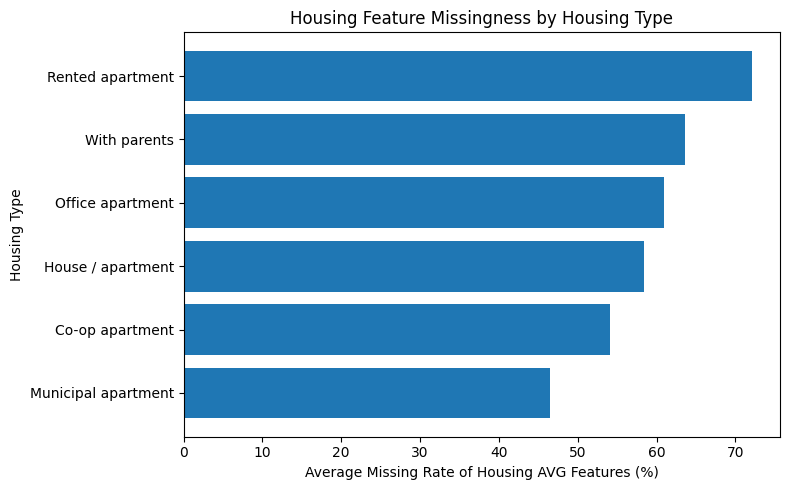

In [49]:
plot_df = housing_missing_by_type.reset_index().sort_values("mean")

plt.figure(figsize=(8, 5))
plt.barh(plot_df["NAME_HOUSING_TYPE"], plot_df["mean"] * 100)

plt.xlabel("Average Missing Rate of Housing AVG Features (%)")
plt.ylabel("Housing Type")
plt.title("Housing Feature Missingness by Housing Type")
plt.tight_layout()
plt.show()

Housing-related variables showed different missing rates across housing types, suggesting that their missingness is not completely random. However, unlike OWN_CAR_AGE, there is no deterministic rule that makes housing information structurally unavailable for one specific housing type. Therefore, we did not assign a special numeric value such as -1 to housing variables. Instead, we used median imputation with missing indicators, so the model can use both the observed housing values and the missingness patterns.

In [51]:
social_cols = [
    'OBS_30_CNT_SOCIAL_CIRCLE',
    'DEF_30_CNT_SOCIAL_CIRCLE',
    'OBS_60_CNT_SOCIAL_CIRCLE',
    'DEF_60_CNT_SOCIAL_CIRCLE'
]

X_current_clean[social_cols].corr()

,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE
OBS_30_CNT_SOCIAL_CIRCLE,1.000000,0.329338,0.998490,0.253499
DEF_30_CNT_SOCIAL_CIRCLE,0.329338,1.000000,0.331571,0.860517
OBS_60_CNT_SOCIAL_CIRCLE,0.998490,0.331571,1.000000,0.255570
DEF_60_CNT_SOCIAL_CIRCLE,0.253499,0.860517,0.255570,1.000000


OBS_30_CNT_SOCIAL_CIRCLE and OBS_60_CNT_SOCIAL_CIRCLE are almost the same. so we removed OBS_60_CNT_SOCIAL_CIRCLE

In [54]:
X_current_clean = X_current_clean.drop(columns=['OBS_60_CNT_SOCIAL_CIRCLE'])

# Summary

removed 46 cols in total
converted binary varibles to 1/0

In [56]:
X_current_clean.to_csv(
    "X_current_clean.csv",
    index=False
)

# Imputation

In [ ]:
import pandas as pd
import numpy as np

missing_like_values = [
    'XNA', 'XAP', 'Unknown', 'unknown',
    'Missing', 'missing',
    'NA', 'N/A', 'nan', 'NaN', ''
]

missing_detail = []

for col in X_current_clean.columns:
    s = X_current_clean[col]
    na_count = s.isna().sum()
    
    missing_types = {}
    
    if na_count > 0:
        missing_types['NaN'] = na_count
    
    if s.dtype == 'object':
        value_counts = s.value_counts(dropna=False)
        
        for val in missing_like_values:
            count = (s == val).sum()
            if count > 0:
                missing_types[val] = count
    
    if len(missing_types) > 0:
        missing_detail.append({
            'column': col,
            'dtype': s.dtype,
            'missing_types': missing_types,
            'num_missing_types': len(missing_types),
            'total_missing_like_count': sum(missing_types.values()),
            'missing_like_rate': sum(missing_types.values()) / len(X_current_clean)
        })

missing_detail_df = pd.DataFrame(missing_detail)

missing_detail_df = missing_detail_df.sort_values(
    by=['num_missing_types', 'missing_like_rate'],
    ascending=[False, False]
)

missing_detail_df

,column,dtype,missing_types,num_missing_types,total_missing_like_count,missing_like_rate
15,COMMONAREA_AVG,float64,{'NaN': 214865},1,214865,0.698723
23,NONLIVINGAPARTMENTS_AVG,float64,{'NaN': 213514},1,213514,0.694330
25,FONDKAPREMONT_MODE,object,{'NaN': 210295},1,210295,0.683862
21,LIVINGAPARTMENTS_AVG,float64,{'NaN': 210199},1,210199,0.683550
19,FLOORSMIN_AVG,float64,{'NaN': 208642},1,208642,0.678486
14,YEARS_BUILD_AVG,float64,{'NaN': 204488},1,204488,0.664978
20,LANDAREA_AVG,float64,{'NaN': 182590},1,182590,0.593767
12,BASEMENTAREA_AVG,float64,{'NaN': 179943},1,179943,0.585160
8,EXT_SOURCE_1,float64,{'NaN': 173378},1,173378,0.563811
24,NONLIVINGAREA_AVG,float64,{'NaN': 169682},1,169682,0.551792


In [58]:
# Check common special numeric values
special_numeric_values = [365243, -1, 999999, 9999999]

numeric_special_summary = []

for col in X_current_clean.select_dtypes(include=['int64', 'float64']).columns:
    for val in special_numeric_values:
        count = (X_current_clean[col] == val).sum()
        if count > 0:
            numeric_special_summary.append({
                'column': col,
                'special_value': val,
                'count': count,
                'rate': count / len(X_current_clean)
            })

numeric_special_summary = pd.DataFrame(numeric_special_summary)
numeric_special_summary.sort_values(['rate', 'column'], ascending=[False, True])

,column,special_value,count,rate
4,OWN_CAR_AGE,-1,202924,0.659892
0,DAYS_EMPLOYED,365243,55374,0.180072
5,DAYS_LAST_PHONE_CHANGE,-1,2812,0.009144
2,DAYS_REGISTRATION,-1,113,0.000367
3,DAYS_ID_PUBLISH,-1,64,0.000208
1,DAYS_EMPLOYED,-1,1,0.000003


In [60]:
# Count abnormal DAYS_EMPLOYED
days_emp_special_count = (X_current_clean['DAYS_EMPLOYED'] == 365243).sum()

# Count ORGANIZATION_TYPE == XNA
org_xna_count = (X_current_clean['ORGANIZATION_TYPE'] == 'XNA').sum()

print("DAYS_EMPLOYED = 365243:", days_emp_special_count)
print("ORGANIZATION_TYPE = XNA:", org_xna_count)

DAYS_EMPLOYED = 365243: 55374
ORGANIZATION_TYPE = XNA: 55374


In [61]:
same_group_check = pd.crosstab(
    X_current_clean['DAYS_EMPLOYED'] == 365243,
    X_current_clean['ORGANIZATION_TYPE'] == 'XNA'
)

same_group_check

ORGANIZATION_TYPE,False,True
DAYS_EMPLOYED,,
False,252137,0
True,0,55374


In [62]:
pd.crosstab(
    X_current_clean['FLAG_EMP_PHONE'],
    X_current_clean['DAYS_EMPLOYED'] == 365243,
    margins=True
)

DAYS_EMPLOYED,False,True,All
FLAG_EMP_PHONE,,,
0,12,55374,55386
1,252125,0,252125
All,252137,55374,307511


In [65]:
special_emp = X_current_clean['DAYS_EMPLOYED'] == 365243

pd.crosstab(
    X_current_clean['NAME_INCOME_TYPE'],
    special_emp,
    margins=True
)

DAYS_EMPLOYED,False,True,All
NAME_INCOME_TYPE,,,
Businessman,10,0,10
Commercial associate,71617,0,71617
Maternity leave,5,0,5
Pensioner,10,55352,55362
State servant,21703,0,21703
Student,18,0,18
Unemployed,0,22,22
Working,158774,0,158774
All,252137,55374,307511


We found DAYS_EMPLOYED == 365243 means they are Pensioner. so we add a feature called IS_PENSIONER.

In [66]:
cat_cols = X_current_clean.select_dtypes(include='object').columns.tolist()

cat_link_summary = []

for col in cat_cols:
    tab = pd.crosstab(X_current_clean[col].fillna('NaN'), special_emp)
    
    if True in tab.columns and False in tab.columns:
        tab['total'] = tab[False] + tab[True]
        tab['special_rate'] = tab[True] / tab['total']
        
        # 每个 categorical 变量里，找 special_emp 比例最高的类别
        top = tab.sort_values('special_rate', ascending=False).head(5)
        
        for level, row in top.iterrows():
            if row['total'] >= 20:   # 避免特别小的类别误导
                cat_link_summary.append({
                    'feature': col,
                    'level': level,
                    'count': int(row['total']),
                    'special_count': int(row[True]),
                    'special_rate': row['special_rate']
                })

cat_link_summary = pd.DataFrame(cat_link_summary)

cat_link_summary = cat_link_summary.sort_values(
    ['special_rate', 'special_count'],
    ascending=[False, False]
)

cat_link_summary.head(30)

,feature,level,count,special_count,special_rate
37,ORGANIZATION_TYPE,XNA,55374,55374,1.000000
9,NAME_INCOME_TYPE,Unemployed,22,22,1.000000
10,NAME_INCOME_TYPE,Pensioner,55362,55352,0.999819
17,NAME_FAMILY_STATUS,Widow,16088,9380,0.583043
27,OCCUPATION_TYPE,NaN,96391,55372,0.574452
12,NAME_EDUCATION_TYPE,Lower secondary,3816,1529,0.400681
4,NAME_TYPE_SUITE,Children,3267,1017,0.311295
2,CODE_GENDER,F,202448,45271,0.223618
5,NAME_TYPE_SUITE,Family,40149,8490,0.211462
13,NAME_EDUCATION_TYPE,Secondary / secondary special,218391,45105,0.206533


In [67]:
num_cols = X_current_clean.select_dtypes(include=['int64', 'float64']).columns.tolist()

num_link_summary = []

for col in num_cols:
    if col == 'DAYS_EMPLOYED':
        continue
    
    s = X_current_clean[col]
    
    # 如果是 binary 变量
    unique_vals = set(s.dropna().unique())
    if unique_vals.issubset({0, 1}):
        tab = pd.crosstab(s, special_emp)
        
        if True in tab.columns and False in tab.columns:
            for val in tab.index:
                total = tab.loc[val].sum()
                special_count = tab.loc[val, True]
                special_rate = special_count / total
                
                if total >= 20:
                    num_link_summary.append({
                        'feature': col,
                        'value': val,
                        'count': int(total),
                        'special_count': int(special_count),
                        'special_rate': special_rate
                    })

num_link_summary = pd.DataFrame(num_link_summary)

num_link_summary = num_link_summary.sort_values(
    ['special_rate', 'special_count'],
    ascending=[False, False]
)

num_link_summary.head(30)

,feature,value,count,special_count,special_rate
4,FLAG_EMP_PHONE,0,55386,55374,0.999783
29,FLAG_DOCUMENT_6,1,27078,24892,0.919270
24,FLAG_DOCUMENT_3,0,89171,29381,0.329491
20,REG_CITY_NOT_WORK_CITY,0,236644,55374,0.233997
6,FLAG_WORK_PHONE,0,246203,55373,0.224908
0,FLAG_OWN_CAR,0,202924,45205,0.222768
22,LIVE_CITY_NOT_WORK_CITY,0,252296,55374,0.219480
3,FLAG_OWN_REALTY,1,213312,42230,0.197973
30,FLAG_DOCUMENT_8,0,282487,54811,0.194030
18,REG_CITY_NOT_LIVE_CITY,0,283472,53969,0.190386


把365243替换成0 代表工作天数为0
增加DAYS_EMPLOYED_missing
ORGANIZATION_TYPE = XNA不变
FLAG_EMP_PHONE  整列删掉 相关性太高
OCCUPATION_TYPE = NaN 改Missing

In [70]:
# 1. Create indicator for special DAYS_EMPLOYED value
X_current_clean['DAYS_EMPLOYED_missing'] = (
    X_current_clean['DAYS_EMPLOYED'] == 365243
).astype(int)

# 2. Replace 365243 with 0
X_current_clean['DAYS_EMPLOYED'] = X_current_clean['DAYS_EMPLOYED'].replace(
    365243, 0
)

# 3. Keep ORGANIZATION_TYPE = XNA unchanged
# No action needed

# 4. Drop FLAG_EMP_PHONE because it is highly redundant with DAYS_EMPLOYED_missing
X_current_clean = X_current_clean.drop(
    columns=['FLAG_EMP_PHONE'],
    errors='ignore'
)

# 5. Replace missing OCCUPATION_TYPE with "Missing"
X_current_clean['OCCUPATION_TYPE'] = (
    X_current_clean['OCCUPATION_TYPE'].fillna('Missing')
)

In [71]:
# Check result
print("DAYS_EMPLOYED = 365243 count:",
      (X_current_clean['DAYS_EMPLOYED'] == 365243).sum())

print("DAYS_EMPLOYED_missing distribution:")
print(X_current_clean['DAYS_EMPLOYED_missing'].value_counts())

print("FLAG_EMP_PHONE in columns:",
      'FLAG_EMP_PHONE' in X_current_clean.columns)

print("OCCUPATION_TYPE missing count:",
      X_current_clean['OCCUPATION_TYPE'].isna().sum())

DAYS_EMPLOYED = 365243 count: 0
DAYS_EMPLOYED_missing distribution:
DAYS_EMPLOYED_missing
0    252137
1     55374
Name: count, dtype: int64
FLAG_EMP_PHONE in columns: False
OCCUPATION_TYPE missing count: 0


In [72]:
X_current_clean.to_csv("X_current_clean.csv", index=False)

Summary

Summary of Findings and Processing

- Missing values were mostly consistent within each variable.
  - Numerical variables mainly used NaN.
  - Categorical variables used NaN, XNA, XAP, or Unknown.
  - High missing rates were mostly found in housing/building-related variables, so we did not remove columns only based on missing rate.

- For housing/building variables:
  - AVG, MODE, and MEDI versions of the same feature were highly redundant.
  - Pairwise Spearman correlations were mostly above 0.95.
  - We kept the AVG version and removed the corresponding MODE and MEDI versions.
  - This reduced duplicated information while keeping the main housing signal.

- For near-zero variance binary features:
  - If one binary value accounted for more than 99.5%, the feature was treated as almost constant.
  - These low-information binary columns were removed.

- For car-related variables:
  - OWN_CAR_AGE was structurally missing for applicants without a car.
  - Since some car owners had car age equal to 0, we did not use 0 as the missing value.
  - Missing OWN_CAR_AGE was filled with -1.

- For social circle variables:
  - OBS_30_CNT_SOCIAL_CIRCLE and OBS_60_CNT_SOCIAL_CIRCLE were almost identical.
  - OBS_60_CNT_SOCIAL_CIRCLE was removed to reduce redundancy.

- For DAYS_EMPLOYED:
  - DAYS_EMPLOYED = 365243 was identified as a structural special value, not a real employment duration.
  - This group mainly represented Pensioner/Unemployed applicants.
  - It was strongly linked with ORGANIZATION_TYPE = XNA, FLAG_EMP_PHONE = 0, and missing OCCUPATION_TYPE.
  - We replaced 365243 with 0 and added DAYS_EMPLOYED_missing.
  - ORGANIZATION_TYPE = XNA was kept unchanged.
  - FLAG_EMP_PHONE was removed because it was highly redundant with DAYS_EMPLOYED_missing.
  - Missing OCCUPATION_TYPE values were filled with “Missing”.